# Lab Example Solutions: Machine Learning with Python

This notebook gives example answers for the Weeks 5–8 lab *Exploring Machine Learning with Python on W3Schools* (`Lab.docx` in the Week 5 **3 Tutorial** folder). It follows the five lab sections in order and works through every topic on the lab sheet: regression, scaling, train/test, classification, the confusion matrix, clustering, grid search, cross-validation, bagging and the ROC curve. Try each W3Schools page yourself first, then compare your work with the answer here.

**The problem.** We reuse two problems from the Week 5 lecture *Regression Problems*: predicting the price of a house from its size (the 47 houses plotted on slide 8) and classifying a tumour as malignant or benign (slide 38). A few small datasets that come with scikit-learn (iris flowers, wines, diabetes patients) fill in the other topics, so the notebook needs no files or downloads.

**How to run it.** Run the cells from top to bottom (**Run → Run All Cells**, or press **Shift + Enter** in each cell). Everything runs in your browser on the course website; the first cell can take a few seconds while the libraries load.

**Expected result.** Each section prints a few numbers and most draw a plot. Highlights: the house-price line rises by about **\$135 per square foot**, and the normal equation and gradient descent from the lecture give the same line; on the tumour data, logistic regression classifies about **99%** of the test tumours correctly, with an area under the ROC curve close to 1.

## 0. Imports

NumPy and pandas hold the data, Matplotlib draws the plots, SciPy provides simple statistics and the dendrogram, and scikit-learn provides the datasets, models and evaluation tools. All of them run in the browser.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.datasets import load_breast_cancer, load_diabetes, load_iris, load_wine
from sklearn.model_selection import (train_test_split, GridSearchCV, cross_val_score,
                                     KFold, StratifiedKFold, LeaveOneOut)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.ensemble import BaggingClassifier
from sklearn import metrics
import warnings
# in the browser, a helper library of scikit-learn prints a harmless deprecation warning; hide it
warnings.filterwarnings("ignore", message="JsProxy.as_object_map", category=RuntimeWarning)

## 1. Introduction to machine learning: describe the data first

The W3Schools introduction starts by describing a list of numbers with the mean, median, mode, standard deviation and percentiles. We do the same for the 47 house prices from lecture slide 8 (in thousands of dollars), next to the size of each house in square feet.

In [2]:
# The 47 houses plotted on lecture slide 8: size in square feet and price in dollars
size = np.array([
    2104, 1600, 2400, 1416, 3000, 1985, 1534, 1427, 1380, 1494, 1940, 2000,
    1890, 4478, 1268, 2300, 1320, 1236, 2609, 3031, 1767, 1888, 1604, 1962,
    3890, 1100, 1458, 2526, 2200, 2637, 1839, 1000, 2040, 3137, 1811, 1437,
    1239, 2132, 4215, 2162, 1664, 2238, 2567, 1200, 852, 1852, 1203])
price = np.array([
    399900, 329900, 369000, 232000, 539900, 299900, 314900, 198999,
    212000, 242500, 239999, 347000, 329999, 699900, 259900, 449900,
    299900, 199900, 499998, 599000, 252900, 255000, 242900, 259900,
    573900, 249900, 464500, 469000, 475000, 299900, 349900, 169900,
    314900, 579900, 285900, 249900, 229900, 345000, 549000, 287000,
    368500, 329900, 314000, 299000, 179900, 299900, 239500]) / 1000  # price in $1000, as on the slide

print("Number of houses:", len(size))
print(f"Mean price:    {np.mean(price):.1f}")
print(f"Median price:  {np.median(price):.1f}")
print(f"Mode of price: {stats.mode(price).mode:.1f}")       # the most common value
print(f"Std of price:  {np.std(price):.1f}")                # typical distance from the mean
print(f"75th percentile of price: {np.percentile(price, 75):.1f}")

Number of houses: 47
Mean price:    340.4
Median price:  299.9
Mode of price: 299.9
Std of price:  123.7
75th percentile of price: 384.4


**What do you notice?** Compare the mean and the median price.

<details><summary>Answer</summary>

The mean (about 340) is higher than the median (about 300). A few very expensive houses (up to 700) pull the mean up, while the median, the middle value, is not affected by them. The prices are *right-skewed*.
</details>

## 2. Regression analysis

### 2.1 Linear regression

W3Schools fits a straight line with `scipy.stats.linregress`. It returns the slope and intercept of the line and the correlation coefficient `r` (close to 1 or −1 means a strong linear relationship). We then use the line to predict the price of a 2000 ft² house, which is the hypothesis $h_\theta(x) = \theta_0 + \theta_1 x$ from the lecture.

In [3]:
line = stats.linregress(size, price)
print(f"slope (theta_1)     = {line.slope:.4f} thousand $ per square foot")
print(f"intercept (theta_0) = {line.intercept:.2f} thousand $")
print(f"r = {line.rvalue:.3f}")

# Predict the price of a 2000 square-foot house with h(x) = theta_0 + theta_1 * x
print(f"Predicted price of a 2000 ft2 house: {line.intercept + line.slope * 2000:.1f} thousand $")

slope (theta_1)     = 0.1345 thousand $ per square foot
intercept (theta_0) = 71.27 thousand $
r = 0.855
Predicted price of a 2000 ft2 house: 340.3 thousand $


The plot shows the data with the fitted line, like the last gradient-descent picture in the lecture (slide 29).

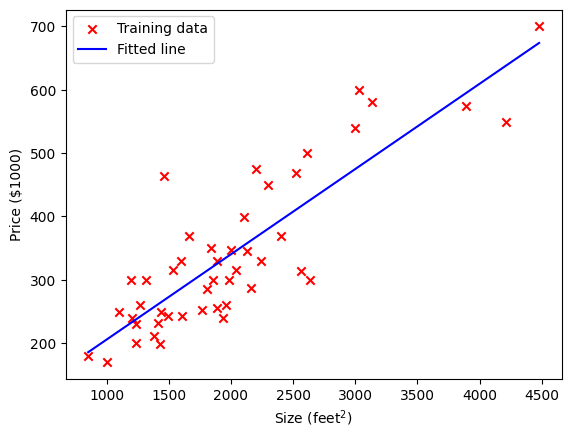

In [4]:
xs = np.linspace(size.min(), size.max(), 100)
plt.scatter(size, price, marker="x", color="red", label="Training data")
plt.plot(xs, line.intercept + line.slope * xs, color="blue", label="Fitted line")
plt.xlabel("Size (feet$^2$)")
plt.ylabel(r"Price (\$1000)")
plt.legend()
plt.show()

### 2.2 The same line with the lecture's two methods

The lecture shows two ways to find $\theta$: the **normal equation** $\theta = (X^TX)^{-1}X^Ty$ (slide 20) and **batch gradient descent** (slides 17–30). Both should give the line above. For gradient descent we first scale the size (slides 32–33) so that a learning rate such as $\alpha = 0.1$ works, and we record the cost $J(\theta)$ after every step to check that it goes down (slide 34).

In [5]:
# Normal equation: add a column of ones for theta_0 (x_0 = 1), then solve (X^T X) theta = X^T y
X = np.column_stack([np.ones(len(size)), size])
theta_normal = np.linalg.solve(X.T @ X, X.T @ price)
print("Normal equation:  theta_0 = %.2f, theta_1 = %.4f" % tuple(theta_normal))

Normal equation:  theta_0 = 71.27, theta_1 = 0.1345


Gradient descent: theta_0 = 71.27, theta_1 = 0.1345


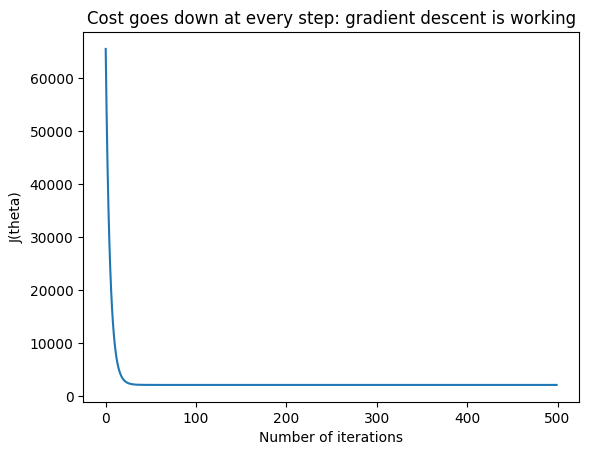

In [6]:
# Gradient descent on the scaled size z = (size - mean) / std
mu, sigma = size.mean(), size.std()
Z = np.column_stack([np.ones(len(size)), (size - mu) / sigma])
m = len(price)

def gradient_descent(alpha, steps):
    theta = np.zeros(2)                       # start with theta = 0
    costs = []
    for _ in range(steps):
        error = Z @ theta - price             # h(x) - y for every house ("batch")
        theta = theta - alpha * (Z.T @ error) / m   # update all theta_j together
        costs.append((error @ error) / (2 * m))     # J(theta) before this step
    return theta, costs

theta_z, costs = gradient_descent(alpha=0.1, steps=500)
# Turn the theta found for the scaled size back into theta for the size in square feet
theta_1 = theta_z[1] / sigma
theta_0 = theta_z[0] - theta_1 * mu
print("Gradient descent: theta_0 = %.2f, theta_1 = %.4f" % (theta_0, theta_1))

plt.plot(costs)
plt.xlabel("Number of iterations")
plt.ylabel("J(theta)")
plt.title("Cost goes down at every step: gradient descent is working")
plt.show()

**Try it:** run gradient descent again with `alpha=0.001` and with `alpha=2.5` and look at the final cost `costs[-1]`.

<details><summary>Answer</summary>

With `alpha=0.001` the cost is still above 25,000 after 500 steps, far from the minimum of about 2,058 (slow convergence). With `alpha=2.5` the cost grows at every step and gradient descent does not converge. This is slide 35: if $\alpha$ is too small, convergence is slow; if it is too large, $J(\theta)$ may not decrease and may not converge.
</details>

### 2.3 Polynomial regression

A polynomial can follow a curved pattern. `np.polyfit` fits one and `r2_score` measures how much of the variation in price the model explains (1 = all of it). We compare a straight line (degree 1) with a parabola (degree 2).

In [7]:
for degree in [1, 2]:
    model = np.poly1d(np.polyfit(size, price, degree))   # least-squares polynomial
    print(f"degree {degree}: R^2 = {metrics.r2_score(price, model(size)):.3f}")

degree 1: R^2 = 0.731
degree 2: R^2 = 0.731


**What do you notice?** The parabola explains no more of the variation than the straight line ($R^2$ = 0.731 for both), so here the simpler straight line is the better choice.

### 2.4 Multiple regression

With several input variables the hypothesis becomes $h_\theta(x) = \theta_0 + \theta_1x_1 + \dots + \theta_nx_n$ (lecture slide 11). W3Schools uses scikit-learn's `LinearRegression` for this. We predict how much a diabetes patient's disease progresses in one year from three measurements: body mass index (bmi), blood pressure (bp) and a blood serum value (s5). The dataset is supplied already scaled.

In [8]:
diabetes = load_diabetes(as_frame=True)
features = ["bmi", "bp", "s5"]
Xd, yd = diabetes.data[features], diabetes.target

reg = LinearRegression().fit(Xd, yd)
print("theta_0 (intercept):", round(reg.intercept_, 1))
for name, coef in zip(features, reg.coef_):
    print(f"theta for {name}: {coef:.1f}")
print(f"R^2 = {reg.score(Xd, yd):.3f}")

theta_0 (intercept): 152.1
theta for bmi: 603.1
theta for bp: 262.3
theta for s5: 543.9
R^2 = 0.480


All three coefficients are positive: a higher bmi, blood pressure or s5 goes with more disease progression, if the other two stay the same.

## 3. Data preprocessing and model evaluation

### 3.1 Scale

Features on very different scales slow gradient descent down and distort distance-based methods such as K-NN. In the wine data, *alcohol* is around 13 while *proline* is in the hundreds. `StandardScaler` gives every feature mean 0 and standard deviation 1. The lecture's mean normalization (slide 33), $(x - \mu)/(\max - \min)$, is another option.

In [9]:
wine = load_wine(as_frame=True)
two = wine.data[["alcohol", "proline"]]
print("Before scaling:\n", two.describe().loc[["mean", "std", "min", "max"]].round(2), "\n")

scaled = pd.DataFrame(StandardScaler().fit_transform(two), columns=two.columns)
print("After StandardScaler:\n", scaled.describe().loc[["mean", "std", "min", "max"]].round(2), "\n")

# Mean normalization of the house sizes, as on lecture slide 33
size_norm = (size - size.mean()) / (size.max() - size.min())
print(f"Mean-normalized house sizes range from {size_norm.min():.2f} to {size_norm.max():.2f}")

Before scaling:
       alcohol  proline
mean    13.00   746.89
std      0.81   314.91
min     11.03   278.00
max     14.83  1680.00 

After StandardScaler:
       alcohol  proline
mean     0.00    -0.00
std      1.00     1.00
min     -2.43    -1.49
max      2.26     2.97 

Mean-normalized house sizes range from -0.32 to 0.68


After `StandardScaler` both features have mean 0 and standard deviation 1 (−0.00 is a tiny rounding error). The mean-normalized house sizes have mean 0 and span a range of exactly 1; here it runs from −0.32 to 0.68, not −0.5 to 0.5, because a few very large houses stretch the top end.

### 3.2 Train/test

To check how a model does on **new** data, we keep 20% of the houses aside as a test set, fit on the other 80% and measure $R^2$ on both parts. A model that does much better on the training set than on the test set is *overfitting*. We compare a straight line with a degree-5 polynomial; the size is scaled first (section 3.1) so that its fifth power stays a manageable number.

In [10]:
z = (size - size.mean()) / size.std()      # scaled size
x_train, x_test, y_train, y_test = train_test_split(z, price, test_size=0.2, random_state=2)
print(len(x_train), "training houses,", len(x_test), "test houses")

for degree in [1, 5]:
    model = np.poly1d(np.polyfit(x_train, y_train, degree))   # fit on the training set only
    r2_train = metrics.r2_score(y_train, model(x_train))
    r2_test = metrics.r2_score(y_test, model(x_test))
    print(f"degree {degree}: R^2 train = {r2_train:.3f}, R^2 test = {r2_test:.3f}")

37 training houses, 10 test houses
degree 1: R^2 train = 0.703, R^2 test = 0.827
degree 5: R^2 train = 0.757, R^2 test = 0.533


**What do you notice?**

<details><summary>Answer</summary>

The degree-5 polynomial fits the training houses better than the straight line ($R^2$ 0.757 against 0.703), but it does much worse on the test houses (0.533 against 0.827): its extra flexibility follows noise in the training data rather than a real pattern. The straight line generalises better.
</details>

## 4. Classification techniques

We now predict a **class** instead of a number: is a breast tumour malignant or benign (lecture slide 38)? The *Breast Cancer Wisconsin* dataset in scikit-learn has 30 measurements for each of 569 tumours. In this dataset class 0 is *malignant* and class 1 is *benign*. We keep 25% of the tumours for testing; `stratify` keeps the same share of each class in both parts.

In [11]:
cancer = load_breast_cancer()
Xc, yc = cancer.data, cancer.target
print("Tumours, measurements:", Xc.shape)
print("Classes:", {str(name): int(count) for name, count in zip(cancer.target_names, np.bincount(yc))})

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.25, stratify=yc, random_state=42)

Tumours, measurements: (569, 30)
Classes: {'malignant': 212, 'benign': 357}


### 4.1 Decision tree

A decision tree asks a sequence of yes/no questions about the measurements (Week 6 lecture). We limit it to 3 levels of questions to keep it simple.

In [12]:
tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(Xc_train, yc_train)
print(f"Decision tree test accuracy: {tree.score(Xc_test, yc_test):.3f}")

Decision tree test accuracy: 0.944


### 4.2 Logistic regression

Logistic regression passes $\theta^Tx$ through the sigmoid $g(z) = 1/(1+e^{-z})$, so the output is a probability between 0 and 1 (lecture slide 39); a tumour is predicted benign when that probability is above 0.5. We scale the measurements first, which helps the solver converge.

In [13]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xc_train, yc_train)
print(f"Logistic regression test accuracy: {logreg.score(Xc_test, yc_test):.3f}")

# h(x) for the first three test tumours: the probability that each one is benign (class 1)
print("P(benign) for 3 test tumours:", logreg.predict_proba(Xc_test[:3])[:, 1].round(3))
print("Predicted classes:           ", logreg.predict(Xc_test[:3]))
print("True classes:                ", yc_test[:3])

Logistic regression test accuracy: 0.986
P(benign) for 3 test tumours: [0.969 0.    0.559]
Predicted classes:            [1 0 1]
True classes:                 [1 0 1]


### 4.3 K-nearest neighbours (K-NN)

K-NN labels a tumour with the majority class of the *k* most similar tumours in the training set (Week 7 lecture). Distances are only fair when the features are on the same scale, so we scale first.

In [14]:
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(Xc_train, yc_train)
print(f"K-NN (k=5) test accuracy: {knn.score(Xc_test, yc_test):.3f}")

K-NN (k=5) test accuracy: 0.979


### 4.4 Confusion matrix

Accuracy alone hides *which* mistakes a model makes. The confusion matrix counts, for each true class (rows), how many tumours were predicted as each class (columns). The classification report adds precision, recall and F1-score, as on lecture slide 44.

[[52  1]
 [ 1 89]]


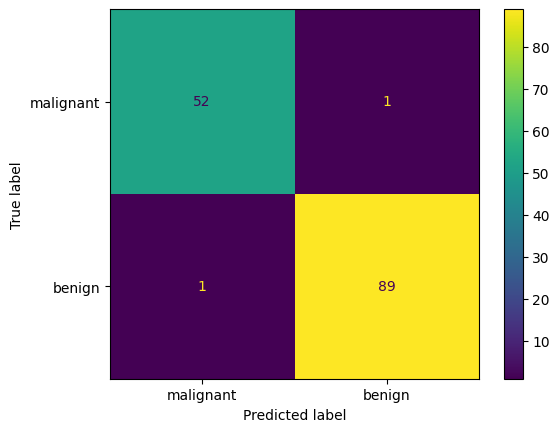

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        53
      benign       0.99      0.99      0.99        90

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143



In [15]:
pred = logreg.predict(Xc_test)
cm = metrics.confusion_matrix(yc_test, pred)
print(cm)
metrics.ConfusionMatrixDisplay(cm, display_labels=cancer.target_names).plot()
plt.show()
print(metrics.classification_report(yc_test, pred, target_names=cancer.target_names))

**Try it:** which cell of the confusion matrix counts the most dangerous mistake, and how many such mistakes did the model make?

<details><summary>Answer</summary>

The worst mistake is a *malignant* tumour predicted as *benign*: first row (true malignant), second column (predicted benign). It happened once here. In practice we would want this number as close to 0 as possible, even at the cost of more false alarms (benign tumours predicted malignant).
</details>

## 5. Clustering and advanced topics

### 5.1 K-means

Clustering finds groups **without** labels. K-means places *k* centres and moves them until each point belongs to its nearest centre. We cluster iris flowers by petal length and width, and use the *elbow method*: the inertia (the sum of squared distances to the nearest centre) drops quickly until the right *k*, then flattens.

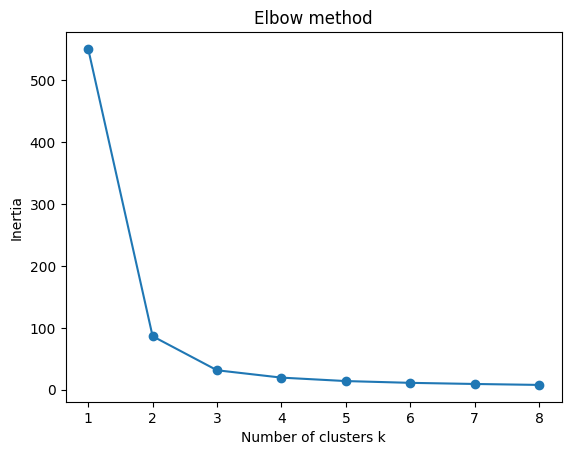

cluster      0   1   2
species               
setosa       0  50   0
versicolor  48   0   2
virginica    4   0  46


In [16]:
iris = load_iris()
petals = iris.data[:, 2:4]          # petal length and petal width (cm)

inertias = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(petals).inertia_ for k in range(1, 9)]
plt.plot(range(1, 9), inertias, marker="o")
plt.xlabel("Number of clusters k")
plt.ylabel("Inertia")
plt.title("Elbow method")
plt.show()

kmeans = KMeans(n_clusters=3, n_init=10, random_state=0).fit(petals)
# Compare the clusters with the real species (which K-means never saw)
print(pd.crosstab(iris.target_names[iris.target], kmeans.labels_,
                  rownames=["species"], colnames=["cluster"]))

The inertia falls steeply up to *k* = 2–3 and then flattens; we choose *k* = 3, and the three clusters match the three species well: only a few versicolor and virginica flowers, whose petals overlap, land in the other cluster.

### 5.2 Hierarchical clustering

Hierarchical (agglomerative) clustering starts with every point as its own cluster and repeatedly merges the two closest clusters. The **dendrogram** shows the order of the merges; cutting it at a chosen height gives the clusters. We use Ward's method on the same petal data and compare the result with K-means using the *adjusted Rand index* (1 = identical groupings).

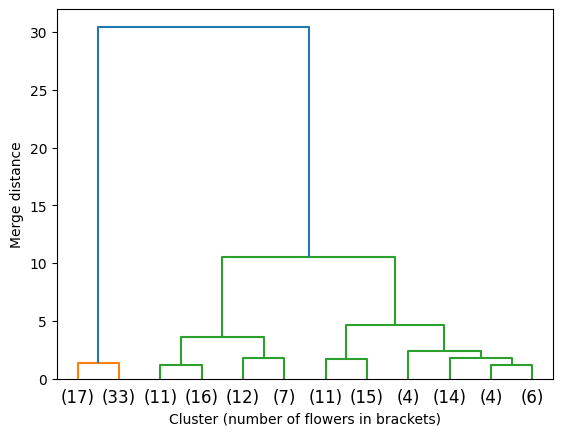

Agreement with K-means (adjusted Rand index): 0.886


In [17]:
merges = linkage(petals, method="ward")
dendrogram(merges, truncate_mode="lastp", p=12)   # show only the last 12 merges
plt.xlabel("Cluster (number of flowers in brackets)")
plt.ylabel("Merge distance")
plt.show()

hier = AgglomerativeClustering(n_clusters=3, linkage="ward").fit(petals)
print(f"Agreement with K-means (adjusted Rand index): {metrics.adjusted_rand_score(kmeans.labels_, hier.labels_):.3f}")

### 5.3 Grid search

Most models have settings (*hyperparameters*) that we choose rather than learn, such as the regularisation strength `C` of logistic regression (smaller `C` = simpler model). Grid search tries each value with 5-fold cross-validation on the **training** set and keeps the best; the test set is used only once, at the end.

In [18]:
grid = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
                    param_grid={"logisticregression__C": [0.01, 0.1, 1, 10, 100]}, cv=5)
grid.fit(Xc_train, yc_train)

for C, score in zip(grid.cv_results_["param_logisticregression__C"], grid.cv_results_["mean_test_score"]):
    print(f"C = {C:>6}: mean cross-validation accuracy = {score:.3f}")
print("Best C:", grid.best_params_["logisticregression__C"])
print(f"Test accuracy with the best C: {grid.score(Xc_test, yc_test):.3f}")

C =   0.01: mean cross-validation accuracy = 0.951
C =    0.1: mean cross-validation accuracy = 0.977
C =    1.0: mean cross-validation accuracy = 0.969
C =   10.0: mean cross-validation accuracy = 0.965
C =  100.0: mean cross-validation accuracy = 0.958
Best C: 0.1
Test accuracy with the best C: 0.979


### 5.4 Cross-validation

One train/test split can be lucky or unlucky. *K-fold* cross-validation splits the data into *k* parts and uses each part once as the test set, so every example is tested once. *Stratified* K-fold keeps the class shares the same in every fold, and *leave-one-out* uses a single example as the test set each time. We score a decision tree on the iris flowers.

In [19]:
clf = DecisionTreeClassifier(random_state=42)
for name, cv in [("K-fold (5)", KFold(n_splits=5, shuffle=True, random_state=42)),
                 ("Stratified K-fold (5)", StratifiedKFold(n_splits=5, shuffle=True, random_state=42)),
                 ("Leave-one-out", LeaveOneOut())]:
    scores = cross_val_score(clf, iris.data, iris.target, cv=cv)
    print(f"{name:22s}: {len(scores):3d} folds, mean accuracy = {scores.mean():.3f}")

K-fold (5)            :   5 folds, mean accuracy = 0.953
Stratified K-fold (5) :   5 folds, mean accuracy = 0.953
Leave-one-out         : 150 folds, mean accuracy = 0.940


### 5.5 Bootstrap aggregation (bagging)

A single decision tree changes a lot when the training data change a little. **Bagging** trains many trees, each on a *bootstrap sample* (drawn with replacement) of the training set, and lets them vote. As on the W3Schools page, we use the wine data and compare one tree with bagged ensembles of 2 to 20 trees.

One decision tree: test accuracy = 0.822


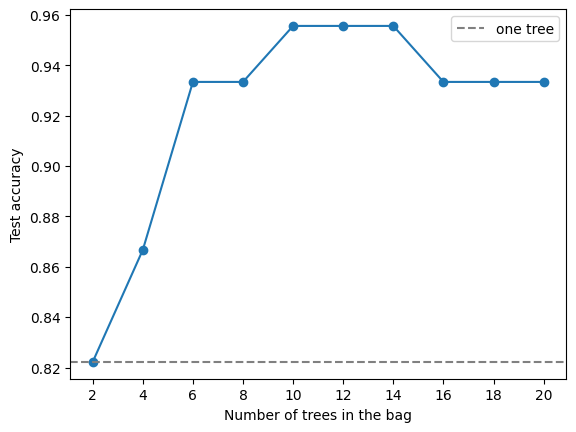

Bagging test accuracies: [0.822 0.867 0.933 0.933 0.956 0.956 0.956 0.933 0.933 0.933]


In [20]:
Xw_train, Xw_test, yw_train, yw_test = train_test_split(
    wine.data, wine.target, test_size=0.25, random_state=22)

single = DecisionTreeClassifier(random_state=22).fit(Xw_train, yw_train)
print(f"One decision tree: test accuracy = {single.score(Xw_test, yw_test):.3f}")

n_trees = list(range(2, 21, 2))
bag_scores = []
for n in n_trees:
    bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=n, random_state=22)
    bag_scores.append(bag.fit(Xw_train, yw_train).score(Xw_test, yw_test))

plt.plot(n_trees, bag_scores, marker="o")
plt.axhline(single.score(Xw_test, yw_test), color="grey", linestyle="--", label="one tree")
plt.xticks(n_trees)
plt.xlabel("Number of trees in the bag")
plt.ylabel("Test accuracy")
plt.legend()
plt.show()
print("Bagging test accuracies:", np.round(bag_scores, 3))

**What do you notice?**

<details><summary>Answer</summary>

With 2 trees the bag scores the same as one tree, but from 4 trees on every bagged ensemble scores higher on these test wines (up to 0.956 against 0.822). Averaging the votes of many trees removes much of the noise that one tree picks up from its particular training sample.
</details>

### 5.6 AUC – ROC curve

A classifier that outputs probabilities can use any threshold, not only 0.5. The **ROC curve** plots the true positive rate against the false positive rate for every threshold, and the **area under the curve (AUC)** sums it up in one number: 1 is perfect and 0.5 is no better than guessing. We compare logistic regression with the decision tree from section 4, using their probabilities that a test tumour is benign.

Logistic regression: AUC = 0.998
Decision tree: AUC = 0.946


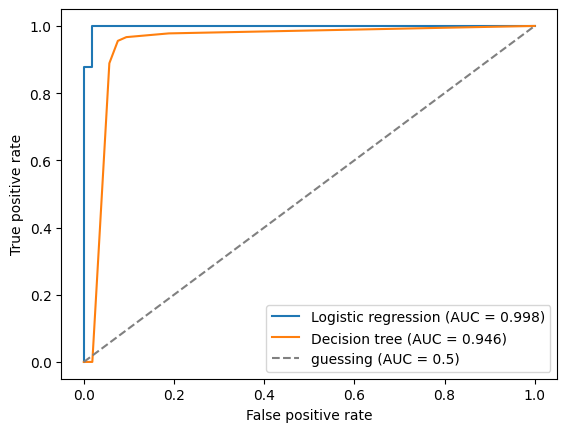

In [21]:
for name, model in [("Logistic regression", logreg), ("Decision tree", tree)]:
    prob = model.predict_proba(Xc_test)[:, 1]          # P(benign) for each test tumour
    fpr, tpr, _ = metrics.roc_curve(yc_test, prob)
    auc = metrics.roc_auc_score(yc_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
    print(f"{name}: AUC = {auc:.3f}")

plt.plot([0, 1], [0, 1], color="grey", linestyle="--", label="guessing (AUC = 0.5)")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend()
plt.show()

## 6. For your lab deliverables

The lab sheet asks for a short report with code and outputs, and for reflections on how these algorithms could work on the dataset you chose for the assessment. Some questions to guide the reflection:

- Is your target a **number** (regression, section 2) or a **class** (classification, section 4)? Or do you want to find groups without labels (clustering, section 5)?
- Do your features need **scaling** (section 3.1)? Which of your models depend on it?
- How will you **evaluate** fairly: a test set, cross-validation, the confusion matrix or the ROC curve?
- Which **hyperparameters** would you tune with grid search?